In [104]:
# For tips on running notebooks in Google Colab, see
# https://docs.pytorch.org/tutorials/beginner/colab
%matplotlib inline

What is [torch.nn]{.title-ref} *really*? `torch.nn` 到底*是*什么？
========================================

**Authors:** Jeremy Howard, [fast.ai](https://www.fast.ai). Thanks to
Rachel Thomas and Francisco Ingham.

**作者：** Jeremy Howard，[fast.ai](https://www.fast.ai)。感谢 Rachel Thomas 和 Francisco Ingham。


We recommend running this tutorial as a notebook, not a script. To
download the notebook (`.ipynb`) file, click the link at the top of the
page.

我们建议以 notebook 的形式运行本教程，而不是作为脚本运行。要下载 notebook（`.ipynb`）文件，请点击页面顶部的链接。

PyTorch provides the elegantly designed modules and classes
[torch.nn](https://pytorch.org/docs/stable/nn.html) ,
[torch.optim](https://pytorch.org/docs/stable/optim.html) ,
[Dataset](https://pytorch.org/docs/stable/data.html?highlight=dataset#torch.utils.data.Dataset)
, and
[DataLoader](https://pytorch.org/docs/stable/data.html?highlight=dataloader#torch.utils.data.DataLoader)
to help you create and train neural networks. In order to fully utilize
their power and customize them for your problem, you need to really
understand exactly what they\'re doing. To develop this understanding,
we will first train basic neural net on the MNIST data set without using
any features from these models; we will initially only use the most
basic PyTorch tensor functionality. Then, we will incrementally add one
feature from `torch.nn`, `torch.optim`, `Dataset`, or `DataLoader` at a
time, showing exactly what each piece does, and how it works to make the
code either more concise, or more flexible.

PyTorch 提供了设计精良的模块和类：[torch.nn](https://pytorch.org/docs/stable/nn.html)、[torch.optim](https://pytorch.org/docs/stable/optim.html)、[Dataset](https://pytorch.org/docs/stable/data.html?highlight=dataset#torch.utils.data.Dataset) 和 [DataLoader](https://pytorch.org/docs/stable/data.html?highlight=dataloader#torch.utils.data.DataLoader)，帮助你创建和训练神经网络。要充分发挥它们的威力，并针对你自己的问题定制它们，你需要真正弄清楚它们到底在做什么。为了建立这种理解，我们会先在 MNIST 数据集上训练一个基础的神经网络，不使用这些模块的任何功能，一开始只用 PyTorch 最基本的张量功能。然后，我们每次从 `torch.nn`、`torch.optim`、`Dataset` 或 `DataLoader` 中加入一个功能，准确展示每一部分做了什么，以及它是如何让代码变得更简洁或更灵活的。

**This tutorial assumes you already have PyTorch installed, and are
familiar with the basics of tensor operations.** (If you\'re familiar
with Numpy array operations, you\'ll find the PyTorch tensor operations
used here nearly identical).

**本教程假设你已经安装好 PyTorch，并且熟悉张量运算的基础知识。**（如果你熟悉 NumPy 数组运算，会发现这里用到的 PyTorch 张量运算几乎和它一模一样。）

MNIST data setup 准备 MNIST 数据
================

We will use the classic
[MNIST](https://yann.lecun.com/exdb/mnist/index.html) dataset, which
consists of black-and-white images of hand-drawn digits (between 0 and
9).

我们将使用经典的 [MNIST](https://yann.lecun.com/exdb/mnist/index.html) 数据集，它由手写数字（0 到 9）的黑白图像组成。

We will use [pathlib](https://docs.python.org/3/library/pathlib.html)
for dealing with paths (part of the Python 3 standard library), and will
download the dataset using
[requests](http://docs.python-requests.org/en/master/). We will only
import modules when we use them, so you can see exactly what\'s being
used at each point.

我们将用 [pathlib](https://docs.python.org/3/library/pathlib.html)（Python 3 标准库的一部分）来处理路径，并用 [requests](http://docs.python-requests.org/en/master/) 下载数据集。我们只在用到某个模块时才导入它，这样你可以清楚地看到每一步具体用了什么。


In [105]:
from pathlib import Path
import requests

DATA_PATH = Path("data")
PATH = DATA_PATH / "mnist"

PATH.mkdir(parents=True, exist_ok=True)

URL = "https://github.com/pytorch/tutorials/raw/main/_static/"
FILENAME = "mnist.pkl.gz"

if not (PATH / FILENAME).exists():
        content = requests.get(URL + FILENAME).content
        (PATH / FILENAME).open("wb").write(content)

This dataset is in numpy array format, and has been stored using pickle,
a python-specific format for serializing data.

这个数据集是 NumPy 数组格式，用 pickle 存储。pickle 是 Python 特有的一种数据序列化格式。


In [106]:
import pickle
import gzip

with gzip.open((PATH / FILENAME).as_posix(), "rb") as f:
        ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding="latin-1")


Each image is 28 x 28, and is being stored as a flattened row of length
784 (=28x28). Let\'s take a look at one; we need to reshape it to 2d
first.

每张图像是 28 x 28 的，被展平成长度为 784（=28x28）的一行来存储。我们来看其中一张；为此需要先把它变形（reshape）成二维。


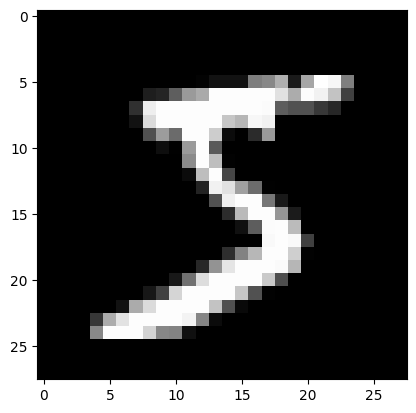

(50000, 784)


In [107]:
from matplotlib import pyplot
import numpy as np

pyplot.imshow(x_train[0].reshape((28, 28)), cmap="gray")
# ``pyplot.show()`` only if not on Colab
try:
    import google.colab
except ImportError:
    pyplot.show()
print(x_train.shape)

PyTorch uses `torch.tensor`, rather than numpy arrays, so we need to
convert our data.

PyTorch 使用的是 `torch.tensor`，而不是 NumPy 数组，所以我们需要转换数据。


In [108]:
import torch 

x_train, y_train, x_valid, y_valid = map(
    torch.tensor, (x_train, y_train, x_valid, y_valid)
) 
n, c = x_train.shape 
print(x_train, y_train) 
print(x_train.shape)
print(y_train.min(), y_train.max())

tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]) tensor([5, 0, 4,  ..., 8, 4, 8])
torch.Size([50000, 784])
tensor(0) tensor(9)


Neural net from scratch (without `torch.nn`) 从零开始搭建神经网络（不用 `torch.nn`）
============================================

Let\'s first create a model using nothing but PyTorch tensor operations.
We\'re assuming you\'re already familiar with the basics of neural
networks. (If you\'re not, you can learn them at
[course.fast.ai](https://course.fast.ai)).

我们先只用 PyTorch 的张量运算来创建一个模型。这里假设你已经熟悉神经网络的基础知识。（如果还不熟悉，可以在 [course.fast.ai](https://course.fast.ai) 上学习。）

PyTorch provides methods to create random or zero-filled tensors, which
we will use to create our weights and bias for a simple linear model.
These are just regular tensors, with one very special addition: we tell
PyTorch that they require a gradient. This causes PyTorch to record all
of the operations done on the tensor, so that it can calculate the
gradient during back-propagation *automatically*!

PyTorch 提供了创建随机张量或全零张量的方法，我们用它们来创建一个简单线性模型的权重（weights）和偏置（bias）。它们就是普通的张量，只多了一个非常特别的设置：我们告诉 PyTorch 它们需要梯度。这样 PyTorch 就会记录对这个张量做过的所有运算，从而在反向传播时*自动*计算梯度！

For the weights, we set `requires_grad` **after** the initialization,
since we don\'t want that step included in the gradient. (Note that a
trailing `_` in PyTorch signifies that the operation is performed
in-place.)

对于权重，我们在初始化**之后**才设置 `requires_grad`，因为我们不希望初始化这一步被算进梯度里。（注意：在 PyTorch 中，方法名末尾的 `_` 表示这个操作是原地（in-place）执行的。）

<div style="background-color: #54c7ec; color: #fff; font-weight: 700; padding-left: 10px; padding-top: 5px; padding-bottom: 5px"><strong>NOTE 注意：</strong></div>

<div style="background-color: #f3f4f7; padding-left: 10px; padding-top: 10px; padding-bottom: 10px; padding-right: 10px">

<p>We are initializing the weights here with<a href="http://proceedings.mlr.press/v9/glorot10a/glorot10a.pdf">Xavier initialisation</a>(by multiplying with <code>1/sqrt(n)</code>).</p>

<p>这里我们用 <a href="http://proceedings.mlr.press/v9/glorot10a/glorot10a.pdf">Xavier 初始化</a>（乘以 <code>1/sqrt(n)</code>）来初始化权重。</p>

</div>



In [109]:
import math 
weights = torch.randn(784, 10) / math.sqrt(784) 
weights.requires_grad_() 
bias = torch.zeros(10, requires_grad=True)

Thanks to PyTorch\'s ability to calculate gradients automatically, we
can use any standard Python function (or callable object) as a model! So
let\'s just write a plain matrix multiplication and broadcasted addition
to create a simple linear model. We also need an activation function, so
we\'ll write [log\_softmax]{.title-ref} and use it. Remember: although
PyTorch provides lots of prewritten loss functions, activation
functions, and so forth, you can easily write your own using plain
python. PyTorch will even create fast accelerator or vectorized CPU code
for your function automatically.

得益于 PyTorch 自动计算梯度的能力，我们可以把任何标准的 Python 函数（或可调用对象）当作模型！所以我们就写一个普通的矩阵乘法加上一个广播加法，来创建一个简单的线性模型。我们还需要一个激活函数，所以会自己写一个 `log_softmax` 并使用它。记住：虽然 PyTorch 提供了很多现成的损失函数、激活函数等，但你也可以很容易地用普通 Python 写出自己的版本。PyTorch 甚至会自动为你的函数生成快速的加速器代码或向量化的 CPU 代码。


In [110]:
# def log_softmax(x):
#     return x - x.exp().sum(-1).log().unsqueeze(-1)

def log_softmax(x):
    return x - x.exp().sum(dim=-1, keepdims=True).log()

def model(xb):
    return log_softmax(xb @ weights + bias)

In the above, the `@` stands for the matrix multiplication operation. We
will call our function on one batch of data (in this case, 64 images).
This is one *forward pass*. Note that our predictions won\'t be any
better than random at this stage, since we start with random weights.

上面代码中的 `@` 表示矩阵乘法运算。我们会在一批（batch）数据上调用这个函数（这里是 64 张图像）。这就是一次*前向传播*（forward pass）。注意，此时我们的预测不会比随机猜测更好，因为我们是从随机权重开始的。


In [111]:
bs = 64   # batch size 

xb = x_train[0:bs]   # a mini-batch from x
preds = model(xb)   # predictions 
preds[0], preds.shape

(tensor([-2.1940, -2.1978, -2.8894, -2.3868, -2.1126, -2.1516, -3.2220, -2.0457,
         -1.9183, -2.5676], grad_fn=<SelectBackward0>),
 torch.Size([64, 10]))

As you see, the `preds` tensor contains not only the tensor values, but
also a gradient function. We\'ll use this later to do backprop.

可以看到，`preds` 张量不仅包含张量的值，还包含一个梯度函数（grad_fn）。之后我们会用它来做反向传播。

Let\'s implement negative log-likelihood to use as the loss function
(again, we can just use standard Python):

我们来实现负对数似然（negative log-likelihood），把它用作损失函数（同样，只用标准 Python 就可以）：


In [112]:
def nll(input, target):
    return -input[range(target.shape[0]), target].mean()

loss_func = nll

Let\'s check our loss with our random model, so we can see if we improve
after a backprop pass later.

我们先看看随机模型的损失是多少，这样之后做完反向传播，就能看出有没有改进。


In [113]:
yb = y_train[0:bs] 
print(loss_func(preds, yb))

tensor(2.3483, grad_fn=<NegBackward0>)


Let\'s also implement a function to calculate the accuracy of our model.
For each prediction, if the index with the largest value matches the
target value, then the prediction was correct.

我们再实现一个计算模型准确率的函数。对于每个预测，如果数值最大的那个位置的索引与目标值相同，这个预测就是正确的。


In [114]:
def accuracy(out, yb):
    preds = torch.argmax(out, dim=1)
    return (preds == yb).float().mean()


Let\'s check the accuracy of our random model, so we can see if our
accuracy improves as our loss improves.

我们看看随机模型的准确率是多少，这样就能看出损失下降时准确率是否也随之提升。


In [115]:
print(accuracy(preds, yb))

tensor(0.0469)


We can now run a training loop. For each iteration, we will:

现在可以运行训练循环了。每次迭代中，我们会：

-   select a mini-batch of data (of size `bs`)
-   use the model to make predictions
-   calculate the loss
-   `loss.backward()` updates the gradients of the model, in this case,
    `weights` and `bias`.

*   选取一个小批量（mini-batch）数据（大小为 `bs`）
*   用模型做出预测
*   计算损失
*   调用 `loss.backward()` 更新模型的梯度，这里就是 `weights` 和 `bias` 的梯度。

We now use these gradients to update the weights and bias. We do this
within the `torch.no_grad()` context manager, because we do not want
these actions to be recorded for our next calculation of the gradient.
You can read more about how PyTorch\'s Autograd records operations
[here](https://pytorch.org/docs/stable/notes/autograd.html).

然后我们用这些梯度来更新权重和偏置。这一步放在 `torch.no_grad()` 上下文管理器中进行，因为我们不希望这些更新操作被记录下来，影响下一次梯度的计算。关于 PyTorch 的 Autograd 如何记录运算，可以[在这里](https://pytorch.org/docs/stable/notes/autograd.html)了解更多。

We then set the gradients to zero, so that we are ready for the next
loop. Otherwise, our gradients would record a running tally of all the
operations that had happened (i.e. `loss.backward()` *adds* the
gradients to whatever is already stored, rather than replacing them).

接着我们把梯度清零，为下一轮循环做好准备。否则，梯度会把之前发生过的所有运算一直累加下去（也就是说，`loss.backward()` 是把梯度*加到*已经存储的值上，而不是替换它们）。

<div style="background-color: #6bcebb; color: #fff; font-weight: 700; padding-left: 10px; padding-top: 5px; padding-bottom: 5px"><strong>TIP 提示：</strong></div>

<div style="background-color: #f3f4f7; padding-left: 10px; padding-top: 10px; padding-bottom: 10px; padding-right: 10px">

<p>You can use the standard python debugger to step through PyTorchcode, allowing you to check the various variable values at each step.Uncomment <code>set_trace()</code> below to try it out.</p>

<p>你可以用标准的 Python 调试器逐步执行 PyTorch 代码，在每一步检查各个变量的值。把下面代码中 <code>set_trace()</code> 的注释去掉就可以试一试。</p>

</div>



In [116]:
from IPython.core.debugger import set_trace 
lr = 0.5   # learning rate 
epochs = 2  

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        # set_trace() 
        start_i = i * bs
        end_i = start_i + bs 
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]
        pred = model(xb) 
        loss = loss_func(pred, yb) 

        loss.backward() 
        with torch.no_grad():
            weights -= weights.grad * lr 
            bias -= bias.grad * lr
            weights.grad.zero_() 
            bias.grad.zero_() 

    

That\'s it: we\'ve created and trained a minimal neural network (in this
case, a logistic regression, since we have no hidden layers) entirely
from scratch!

就这样：我们完全从零开始，创建并训练了一个最简单的神经网络（这里其实是一个逻辑回归，因为没有隐藏层）！

Let\'s check the loss and accuracy and compare those to what we got
earlier. We expect that the loss will have decreased and accuracy to
have increased, and they have.

我们来看看损失和准确率，并与之前的结果比较。我们预期损失会下降、准确率会上升，结果也确实如此。


In [117]:
print(loss_func(model(xb), yb), accuracy(model(xb), yb))

tensor(0.0804, grad_fn=<NegBackward0>) tensor(1.)


Using `torch.nn.functional` 使用 `torch.nn.functional`
===========================

We will now refactor our code, so that it does the same thing as before,
only we\'ll start taking advantage of PyTorch\'s `nn` classes to make it
more concise and flexible. At each step from here, we should be making
our code one or more of: shorter, more understandable, and/or more
flexible.

现在我们来重构代码，让它做和之前完全一样的事情，只是开始利用 PyTorch 的 `nn` 类，让代码更简洁、更灵活。从这里开始的每一步，都应该让代码在以下一个或多个方面有所改进：更短、更容易理解、更灵活。

The first and easiest step is to make our code shorter by replacing our
hand-written activation and loss functions with those from
`torch.nn.functional` (which is generally imported into the namespace
`F` by convention). This module contains all the functions in the
`torch.nn` library (whereas other parts of the library contain classes).
As well as a wide range of loss and activation functions, you\'ll also
find here some convenient functions for creating neural nets, such as
pooling functions. (There are also functions for doing convolutions,
linear layers, etc, but as we\'ll see, these are usually better handled
using other parts of the library.)

第一步也是最简单的一步：用 `torch.nn.functional` 中的函数替换我们手写的激活函数和损失函数，让代码更短（按照惯例，这个模块通常以 `F` 这个名字导入）。这个模块包含了 `torch.nn` 库中所有的函数（而库的其他部分包含的是类）。除了各种各样的损失函数和激活函数，这里还有一些创建神经网络时很方便的函数，比如池化函数。（这里也有做卷积、线性层等的函数，但我们之后会看到，这些通常用库的其他部分来处理会更好。）

If you\'re using negative log likelihood loss and log softmax
activation, then Pytorch provides a single function `F.cross_entropy`
that combines the two. So we can even remove the activation function
from our model.

如果你用的是负对数似然损失加上 log softmax 激活，PyTorch 提供了一个把两者合二为一的函数 `F.cross_entropy`。所以我们甚至可以把激活函数从模型中去掉。


In [118]:
import torch.nn.functional as F 

loss_func = F.cross_entropy 

def model(xb):
    return xb @ weights + bias 


Note that we no longer call `log_softmax` in the `model` function.
Let\'s confirm that our loss and accuracy are the same as before:

注意，我们在 `model` 函数中不再调用 `log_softmax` 了。我们来确认一下损失和准确率与之前相同：


In [119]:
print(loss_func(model(xb), yb), accuracy(model(xb), yb))

tensor(0.0804, grad_fn=<NllLossBackward0>) tensor(1.)


Refactor using `nn.Module` 用 `nn.Module` 重构
==========================

Next up, we\'ll use `nn.Module` and `nn.Parameter`, for a clearer and
more concise training loop. We subclass `nn.Module` (which itself is a
class and able to keep track of state). In this case, we want to create
a class that holds our weights, bias, and method for the forward step.
`nn.Module` has a number of attributes and methods (such as
`.parameters()` and `.zero_grad()`) which we will be using.

接下来，我们用 `nn.Module` 和 `nn.Parameter` 让训练循环更清晰、更简洁。我们写一个 `nn.Module` 的子类（`nn.Module` 本身是一个类，能够记录状态）。这里我们想创建一个类，用来保存权重、偏置，以及前向传播的方法。`nn.Module` 有许多我们会用到的属性和方法（比如 `.parameters()` 和 `.zero_grad()`）。

<div style="background-color: #54c7ec; color: #fff; font-weight: 700; padding-left: 10px; padding-top: 5px; padding-bottom: 5px"><strong>NOTE 注意：</strong></div>

<div style="background-color: #f3f4f7; padding-left: 10px; padding-top: 10px; padding-bottom: 10px; padding-right: 10px">

<p><code>nn.Module</code> (uppercase M) is a PyTorch specific concept, and is aclass we'll be using a lot. <code>nn.Module</code> is not to be confused with the Pythonconcept of a (lowercase <code>m</code>) <a href="https://docs.python.org/3/tutorial/modules.html">module</a>,which is a file of Python code that can be imported.</p>

<p><code>nn.Module</code>（大写 M）是 PyTorch 特有的概念，是一个我们会经常用到的类。不要把 <code>nn.Module</code> 和 Python 中（小写 <code>m</code> 的）<a href="https://docs.python.org/3/tutorial/modules.html">模块（module）</a>概念混淆，后者指的是一个可以被导入的 Python 代码文件。</p>

</div>



In [120]:
from torch import nn 

class Mnist_Logistic(nn.Module):
    def __init__(self):
        super().__init__() 
        self.weights = nn.Parameter(torch.randn(784, 10) / math.sqrt(784))
        self.bias = nn.Parameter(torch.zeros(10))

    def forward(self, xb):
        return xb @ self.weights + self.bias 
    

Since we\'re now using an object instead of just using a function, we
first have to instantiate our model:

因为现在用的是一个对象，而不只是一个函数，所以我们要先实例化模型：


In [121]:
model = Mnist_Logistic()

Now we can calculate the loss in the same way as before. Note that
`nn.Module` objects are used as if they are functions (i.e they are
*callable*), but behind the scenes Pytorch will call our `forward`
method automatically.

现在可以像之前一样计算损失了。注意，`nn.Module` 对象可以像函数一样使用（也就是说它们是*可调用的*），而在背后，PyTorch 会自动调用我们写的 `forward` 方法。


In [122]:
print(loss_func(model(xb), yb))

tensor(2.4230, grad_fn=<NllLossBackward0>)


Previously for our training loop we had to update the values for each
parameter by name, and manually zero out the grads for each parameter
separately, like this:

之前在训练循环中，我们必须按名字逐个更新每个参数的值，并且手动把每个参数的梯度分别清零，像这样：

``` {.python}
with torch.no_grad():
    weights -= weights.grad * lr
    bias -= bias.grad * lr
    weights.grad.zero_()
    bias.grad.zero_()
```

Now we can take advantage of model.parameters() and model.zero\_grad()
(which are both defined by PyTorch for `nn.Module`) to make those steps
more concise and less prone to the error of forgetting some of our
parameters, particularly if we had a more complicated model:

现在我们可以利用 `model.parameters()` 和 `model.zero_grad()`（两者都是 PyTorch 为 `nn.Module` 定义好的），让这些步骤更简洁，也更不容易出现漏掉某些参数的错误，尤其是在模型更复杂的时候：

``` {.python}
with torch.no_grad():
    for p in model.parameters(): p -= p.grad * lr
    model.zero_grad()
```

We\'ll wrap our little training loop in a `fit` function so we can run
it again later.

我们把这个小小的训练循环包装进一个 `fit` 函数，方便之后再次运行。


In [123]:
def fit():
    for epoch in range(epochs):
        for i in range((n - 1) // bs + 1):
            start_i = i * bs 
            end_i = start_i + bs 
            xb = x_train[start_i:end_i]
            yb = y_train[start_i:end_i]
            pred = model(xb) 
            loss = loss_func(pred, yb)

            loss.backward() 

            with torch.no_grad():
                for p in model.parameters():
                    p -= p.grad * lr 
                model.zero_grad()

fit()

Let\'s double-check that our loss has gone down:

我们再确认一下损失已经下降了：


In [124]:
print(loss_func(model(xb), yb))

tensor(0.0814, grad_fn=<NllLossBackward0>)


Refactor using `nn.Linear` 用 `nn.Linear` 重构
==========================

We continue to refactor our code. Instead of manually defining and
initializing `self.weights` and `self.bias`, and calculating
`xb  @ self.weights + self.bias`, we will instead use the Pytorch class
[nn.Linear](https://pytorch.org/docs/stable/nn.html#linear-layers) for a
linear layer, which does all that for us. Pytorch has many types of
predefined layers that can greatly simplify our code, and often makes it
faster too.

我们继续重构代码。不再手动定义和初始化 `self.weights` 和 `self.bias`，也不再手动计算 `xb @ self.weights + self.bias`，而是改用 PyTorch 的线性层类 [nn.Linear](https://pytorch.org/docs/stable/nn.html#linear-layers)，它会替我们完成这些工作。PyTorch 有许多预定义好的层，可以大大简化我们的代码，而且通常还能让代码跑得更快。


In [125]:
class Mnist_Logistic(nn.Module):
    def __init__(self):
        super().__init__() 
        self.lin = nn.Linear(784, 10) 

    def forward(self, xb):
        return self.lin(xb)

We instantiate our model and calculate the loss in the same way as
before:

我们像之前一样实例化模型并计算损失：


In [126]:
model = Mnist_Logistic()
print(loss_func(model(xb), yb))

tensor(2.2695, grad_fn=<NllLossBackward0>)


We are still able to use our same `fit` method as before.

我们仍然可以使用之前那个 `fit` 方法。


In [127]:
fit()

print(loss_func(model(xb), yb))

tensor(0.0836, grad_fn=<NllLossBackward0>)


Refactor using `torch.optim` 用 `torch.optim` 重构
============================

Pytorch also has a package with various optimization algorithms,
`torch.optim`. We can use the `step` method from our optimizer to take a
forward step, instead of manually updating each parameter.

PyTorch 还有一个包含各种优化算法的包：`torch.optim`。我们可以调用优化器的 `step` 方法来前进一步（更新一次参数），而不用手动更新每个参数。

This will let us replace our previous manually coded optimization step:

这样我们就可以把之前手写的优化步骤：

``` {.python}
with torch.no_grad():
    for p in model.parameters(): p -= p.grad * lr
    model.zero_grad()
```

and instead use just:

替换成只有这两行：

``` {.python}
opt.step()
opt.zero_grad()
```

(`optim.zero_grad()` resets the gradient to 0 and we need to call it
before computing the gradient for the next minibatch.)

（`optim.zero_grad()` 会把梯度重置为 0，在计算下一个小批量的梯度之前，我们需要调用它。）


In [128]:
from torch import optim

We\'ll define a little function to create our model and optimizer so we
can reuse it in the future.

我们定义一个小函数来创建模型和优化器，方便以后重复使用。


In [129]:
def get_model():
    model = Mnist_Logistic()
    return model, optim.SGD(model.parameters(), lr=lr)

model, opt = get_model()
print(loss_func(model(xb), yb))

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        start_i = i * bs
        end_i = start_i + bs
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(2.3120, grad_fn=<NllLossBackward0>)
tensor(0.0823, grad_fn=<NllLossBackward0>)


Refactor using Dataset 用 Dataset 重构
======================

PyTorch has an abstract Dataset class. A Dataset can be anything that
has a `__len__` function (called by Python\'s standard `len` function)
and a `__getitem__` function as a way of indexing into it. [This
tutorial](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html)
walks through a nice example of creating a custom
`FacialLandmarkDataset` class as a subclass of `Dataset`.

PyTorch 有一个抽象的 Dataset 类。任何东西只要有 `__len__` 函数（被 Python 的标准 `len` 函数调用）和 `__getitem__` 函数（用来按索引取数据），就可以是一个 Dataset。[这篇教程](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html)给出了一个很好的例子：创建一个自定义的 `FacialLandmarkDataset` 类，作为 `Dataset` 的子类。

PyTorch\'s
[TensorDataset](https://pytorch.org/docs/stable/_modules/torch/utils/data/dataset.html#TensorDataset)
is a Dataset wrapping tensors. By defining a length and way of indexing,
this also gives us a way to iterate, index, and slice along the first
dimension of a tensor. This will make it easier to access both the
independent and dependent variables in the same line as we train.

PyTorch 的 [TensorDataset](https://pytorch.org/docs/stable/_modules/torch/utils/data/dataset.html#TensorDataset) 是一个包装了张量的 Dataset。它定义了长度和索引方式，因此也让我们可以沿着张量的第一个维度进行迭代、索引和切片。这样在训练时，就能更方便地在同一行代码里同时取出自变量（输入）和因变量（标签）。


In [130]:
from torch.utils.data import TensorDataset

Both `x_train` and `y_train` can be combined in a single
`TensorDataset`, which will be easier to iterate over and slice.

`x_train` 和 `y_train` 可以合并到同一个 `TensorDataset` 中，这样迭代和切片都更方便。


In [131]:
train_ds = TensorDataset(x_train, y_train)

Previously, we had to iterate through minibatches of `x` and `y` values
separately:

之前，我们必须分别遍历 `x` 和 `y` 的小批量：

``` {.python}
xb = x_train[start_i:end_i]
yb = y_train[start_i:end_i]
```

Now, we can do these two steps together:

现在，我们可以把这两步合在一起做：

``` {.python}
xb,yb = train_ds[i*bs : i*bs+bs]
```


In [132]:
model, opt = get_model()

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        xb, yb = train_ds[i * bs: i * bs + bs]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(0.0819, grad_fn=<NllLossBackward0>)


Refactor using `DataLoader` 用 `DataLoader` 重构
===========================

PyTorch\'s `DataLoader` is responsible for managing batches. You can
create a `DataLoader` from any `Dataset`. `DataLoader` makes it easier
to iterate over batches. Rather than having to use
`train_ds[i*bs : i*bs+bs]`, the `DataLoader` gives us each minibatch
automatically.

PyTorch 的 `DataLoader` 负责管理批次（batch）。你可以从任何 `Dataset` 创建一个 `DataLoader`。`DataLoader` 让按批次遍历数据变得更容易：不用再写 `train_ds[i*bs : i*bs+bs]`，`DataLoader` 会自动把每个小批量交给我们。


In [133]:
from torch.utils.data import DataLoader

train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs)

Previously, our loop iterated over batches `(xb, yb)` like this:

之前，我们的循环是这样遍历批次 `(xb, yb)` 的：

``` {.python}
for i in range((n-1)//bs + 1):
    xb,yb = train_ds[i*bs : i*bs+bs]
    pred = model(xb)
```

Now, our loop is much cleaner, as `(xb, yb)` are loaded automatically
from the data loader:

现在，循环简洁多了，因为 `(xb, yb)` 会自动从数据加载器中取出：

``` {.python}
for xb,yb in train_dl:
    pred = model(xb)
```


In [134]:
model, opt = get_model()

for epoch in range(epochs):
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))

tensor(0.0812, grad_fn=<NllLossBackward0>)


Thanks to PyTorch\'s `nn.Module`, `nn.Parameter`, `Dataset`, and
`DataLoader`, our training loop is now dramatically smaller and easier
to understand. Let\'s now try to add the basic features necessary to
create effective models in practice.

得益于 PyTorch 的 `nn.Module`、`nn.Parameter`、`Dataset` 和 `DataLoader`，我们的训练循环现在大大缩短，也更容易理解了。接下来，我们试着加入一些在实践中构建有效模型所必需的基本功能。

Add validation 加入验证
==============

In section 1, we were just trying to get a reasonable training loop set
up for use on our training data. In reality, you **always** should also
have a [validation
set](https://www.fast.ai/2017/11/13/validation-sets/), in order to
identify if you are overfitting.

在第 1 部分，我们只是想搭建一个能在训练数据上使用的、合理的训练循环。而在实际中，你**总是**应该再准备一个[验证集](https://www.fast.ai/2017/11/13/validation-sets/)，用来判断模型是否过拟合。

Shuffling the training data is
[important](https://www.quora.com/Does-the-order-of-training-data-matter-when-training-neural-networks)
to prevent correlation between batches and overfitting. On the other
hand, the validation loss will be identical whether we shuffle the
validation set or not. Since shuffling takes extra time, it makes no
sense to shuffle the validation data.

打乱训练数据对于避免批次之间的相关性和过拟合是[很重要的](https://www.quora.com/Does-the-order-of-training-data-matter-when-training-neural-networks)。另一方面，无论是否打乱验证集，验证损失都完全一样。既然打乱需要额外的时间，打乱验证数据就没有意义。

We\'ll use a batch size for the validation set that is twice as large as
that for the training set. This is because the validation set does not
need backpropagation and thus takes less memory (it doesn\'t need to
store the gradients). We take advantage of this to use a larger batch
size and compute the loss more quickly.

验证集的批大小我们设为训练集的两倍。这是因为验证集不需要反向传播，所以占用的内存更少（不需要存储梯度）。我们利用这一点使用更大的批大小，更快地算出损失。


In [135]:
train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True)

valid_ds = TensorDataset(x_valid, y_valid)
valid_dl = DataLoader(valid_ds, batch_size=bs * 2)

We will calculate and print the validation loss at the end of each
epoch.

我们会在每个 epoch（轮次）结束时计算并打印验证损失。

(Note that we always call `model.train()` before training, and
`model.eval()` before inference, because these are used by layers such
as `nn.BatchNorm2d` and `nn.Dropout` to ensure appropriate behavior for
these different phases.)

（注意，我们总是在训练前调用 `model.train()`，在推理前调用 `model.eval()`。因为 `nn.BatchNorm2d` 和 `nn.Dropout` 这类层会根据这个设置，在不同阶段表现出相应的正确行为。）


In [136]:
model, opt = get_model()

for epoch in range(epochs):
    model.train()
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

    model.eval()
    with torch.no_grad():
        valid_loss = sum(loss_func(model(xb), yb) for xb, yb in valid_dl)

    print(epoch, valid_loss / len(valid_dl))

0 tensor(0.3156)
1 tensor(0.2818)


Create fit() and get\_data() 创建 fit() 和 get\_data()
============================

We\'ll now do a little refactoring of our own. Since we go through a
similar process twice of calculating the loss for both the training set
and the validation set, let\'s make that into its own function,
`loss_batch`, which computes the loss for one batch.

现在我们自己来做一点重构。由于计算训练集损失和验证集损失的过程很相似，要做两遍，我们就把它提取成一个单独的函数 `loss_batch`，用来计算一个批次的损失。

We pass an optimizer in for the training set, and use it to perform
backprop. For the validation set, we don\'t pass an optimizer, so the
method doesn\'t perform backprop.

对于训练集，我们传入一个优化器，并用它执行反向传播。对于验证集，我们不传优化器，这样这个函数就不会执行反向传播。


In [137]:
def loss_batch(model, loss_func, xb, yb, opt=None):
    loss = loss_func(model(xb), yb)

    if opt is not None:
        loss.backward()
        opt.step()
        opt.zero_grad()

    return loss.item(), len(xb)

`fit` runs the necessary operations to train our model and compute the
training and validation losses for each epoch.

`fit` 执行训练模型所需的操作，并在每个 epoch 计算训练损失和验证损失。


In [138]:
import numpy as np

def fit(epochs, model, loss_func, opt, train_dl, valid_dl):
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_dl:
            loss_batch(model, loss_func, xb, yb, opt)

        model.eval()
        with torch.no_grad():
            losses, nums = zip(
                *[loss_batch(model, loss_func, xb, yb) for xb, yb in valid_dl]
            )
        val_loss = np.sum(np.multiply(losses, nums)) / np.sum(nums)

        print(epoch, val_loss)

`get_data` returns dataloaders for the training and validation sets.

`get_data` 返回训练集和验证集的数据加载器（DataLoader）。


In [139]:
def get_data(train_ds, valid_ds, bs):
    return (
        DataLoader(train_ds, batch_size=bs, shuffle=True),
        DataLoader(valid_ds, batch_size=bs * 2),
    )

Now, our whole process of obtaining the data loaders and fitting the
model can be run in 3 lines of code:

现在，获取数据加载器并训练模型的整个过程，只需 3 行代码就能完成：


In [140]:
train_dl, valid_dl = get_data(train_ds, valid_ds, bs)
model, opt = get_model()
fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.29365373486280444
1 0.34444468091726305


You can use these basic 3 lines of code to train a wide variety of
models. Let\'s see if we can use them to train a convolutional neural
network (CNN)!

你可以用这基本的 3 行代码训练各种各样的模型。我们来看看能不能用它们训练一个卷积神经网络（CNN）！

Switch to CNN 换成 CNN
=============

We are now going to build our neural network with three convolutional
layers. Because none of the functions in the previous section assume
anything about the model form, we\'ll be able to use them to train a CNN
without any modification.

现在我们要用三个卷积层来搭建神经网络。因为上一节中的函数都没有对模型的形式做任何假设，所以不用做任何修改，就能直接用它们来训练 CNN。

We will use PyTorch\'s predefined
[Conv2d](https://pytorch.org/docs/stable/nn.html#torch.nn.Conv2d) class
as our convolutional layer. We define a CNN with 3 convolutional layers.
Each convolution is followed by a ReLU. At the end, we perform an
average pooling. (Note that `view` is PyTorch\'s version of Numpy\'s
`reshape`)

我们使用 PyTorch 预定义的 [Conv2d](https://pytorch.org/docs/stable/nn.html#torch.nn.Conv2d) 类作为卷积层，定义一个包含 3 个卷积层的 CNN。每个卷积后面都接一个 ReLU。最后做一次平均池化。（注意，`view` 相当于 PyTorch 版本的 NumPy `reshape`。）


In [141]:
class Mnist_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1)
        self.conv2 = nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1)

    def forward(self, xb):
        xb = xb.view(-1, 1, 28, 28)
        xb = F.relu(self.conv1(xb))
        xb = F.relu(self.conv2(xb))
        xb = F.relu(self.conv3(xb))
        xb = F.avg_pool2d(xb, 4)
        return xb.view(-1, xb.size(1))

lr = 0.1

[Momentum](https://cs231n.github.io/neural-networks-3/#sgd) is a
variation on stochastic gradient descent that takes previous updates
into account as well and generally leads to faster training.

[动量（Momentum）](https://cs231n.github.io/neural-networks-3/#sgd)是随机梯度下降的一种变体，它会把之前的更新也考虑进来，通常能让训练更快。


In [ ]:
model = Mnist_CNN()
opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.400718216753006


Using `nn.Sequential` 使用 `nn.Sequential`
=====================

`torch.nn` has another handy class we can use to simplify our code:
[Sequential](https://pytorch.org/docs/stable/nn.html#torch.nn.Sequential)
. A `Sequential` object runs each of the modules contained within it, in
a sequential manner. This is a simpler way of writing our neural
network.

`torch.nn` 还有一个好用的类可以简化代码：[Sequential](https://pytorch.org/docs/stable/nn.html#torch.nn.Sequential)。`Sequential` 对象会按顺序依次运行它包含的每个模块。用它来写神经网络更简单。

To take advantage of this, we need to be able to easily define a
**custom layer** from a given function. For instance, PyTorch doesn\'t
have a [view]{.title-ref} layer, and we need to create one for our
network. `Lambda` will create a layer that we can then use when defining
a network with `Sequential`.

为了用上它，我们需要能方便地用一个给定的函数定义一个**自定义层**。比如，PyTorch 没有 `view` 层，我们需要为网络自己创建一个。下面的 `Lambda` 会创建这样一个层，之后用 `Sequential` 定义网络时就可以使用它。


In [ ]:
class Lambda(nn.Module):
    def __init__(self, func):
        super().__init__()
        self.func = func

    def forward(self, x):
        return self.func(x)


def preprocess(x):
    return x.view(-1, 1, 28, 28)

The model created with `Sequential` is simple:

用 `Sequential` 创建的模型很简单：


In [ ]:
model = nn.Sequential(
    Lambda(preprocess),
    nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.AvgPool2d(4),
    Lambda(lambda x: x.view(x.size(0), -1)),
)

opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.33420969073772433
1 0.22933110742568968


Wrapping `DataLoader` 包装 `DataLoader`
=====================

Our CNN is fairly concise, but it only works with MNIST, because:

我们的 CNN 已经相当简洁了，但它只适用于 MNIST，因为：

:   -   It assumes the input is a 28\*28 long vector
    -   It assumes that the final CNN grid size is 4\*4 (since that\'s
        the average pooling kernel size we used)

*   它假设输入是一个长度为 28\*28 的向量；
*   它假设 CNN 最后输出的网格大小是 4\*4（因为我们用的平均池化核大小就是 4）。

Let\'s get rid of these two assumptions, so our model works with any 2d
single channel image. First, we can remove the initial Lambda layer by
moving the data preprocessing into a generator:

我们来去掉这两个假设，让模型能处理任意的二维单通道图像。首先，把数据预处理移到一个生成器里，这样就可以去掉开头的 Lambda 层：


In [ ]:
def preprocess(x, y):
    return x.view(-1, 1, 28, 28), y


class WrappedDataLoader:
    def __init__(self, dl, func):
        self.dl = dl
        self.func = func

    def __len__(self):
        return len(self.dl)

    def __iter__(self):
        for b in self.dl:
            yield (self.func(*b))

train_dl, valid_dl = get_data(train_ds, valid_ds, bs)
train_dl = WrappedDataLoader(train_dl, preprocess)
valid_dl = WrappedDataLoader(valid_dl, preprocess)

Next, we can replace `nn.AvgPool2d` with `nn.AdaptiveAvgPool2d`, which
allows us to define the size of the *output* tensor we want, rather than
the *input* tensor we have. As a result, our model will work with any
size input.

接下来，我们可以把 `nn.AvgPool2d` 换成 `nn.AdaptiveAvgPool2d`。它让我们指定想要的*输出*张量的大小，而不是我们已有的*输入*张量的大小。这样一来，模型就能处理任意大小的输入。


In [ ]:
model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),
    Lambda(lambda x: x.view(x.size(0), -1)),
)

opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

Let\'s try it out:

我们来试一试：


In [ ]:
fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.39085803947448733
1 0.26746123667955396


Using your
[Accelerator](https://pytorch.org/docs/stable/torch.html#accelerators) 使用你的加速器
\-\-\-\-\-\-\-\-\-\-\-\-\-\--

If you\'re lucky enough to have access to an accelerator such as CUDA
(you can rent one for about \$0.50/hour from most cloud providers) you
can use it to speed up your code. First check that your accelerator is
working in Pytorch:

如果你足够幸运，能用上 CUDA 这类加速器（大多数云服务商都能以大约每小时 0.5 美元的价格租到），就可以用它来加速代码。首先检查一下你的加速器在 PyTorch 中能否正常工作：


In [ ]:
# If the current accelerator is available, we will use it. Otherwise, we use the CPU.
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using mps device


Let\'s update `preprocess` to move batches to the accelerator:

我们更新 `preprocess`，把每个批次移到加速器上：


In [ ]:
def preprocess(x, y):
    return x.view(-1, 1, 28, 28).to(device), y.to(device)


train_dl, valid_dl = get_data(train_ds, valid_ds, bs)
train_dl = WrappedDataLoader(train_dl, preprocess)
valid_dl = WrappedDataLoader(valid_dl, preprocess)

Finally, we can move our model to the accelerator.

最后，我们可以把模型移到加速器上。


In [ ]:
model.to(device)
opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

You should find it runs faster now:

你应该会发现现在运行得更快了：


In [ ]:
fit(epochs, model, loss_func, opt, train_dl, valid_dl)

0 0.21925866123437882
1 0.17678150642216206


Closing thoughts 总结
================

We now have a general data pipeline and training loop which you can use
for training many types of models using Pytorch. To see how simple
training a model can now be, take a look at the [mnist\_sample
notebook](https://github.com/fastai/fastai_dev/blob/master/dev_nb/mnist_sample.ipynb).

现在我们有了一套通用的数据流水线和训练循环，可以用 PyTorch 训练许多类型的模型。想看看现在训练一个模型能有多简单，可以看看 [mnist\_sample notebook](https://github.com/fastai/fastai_dev/blob/master/dev_nb/mnist_sample.ipynb)。

Of course, there are many things you\'ll want to add, such as data
augmentation, hyperparameter tuning, monitoring training, transfer
learning, and so forth. These features are available in the fastai
library, which has been developed using the same design approach shown
in this tutorial, providing a natural next step for practitioners
looking to take their models further.

当然，你还会想加入很多东西，比如数据增强、超参数调优、训练监控、迁移学习等等。这些功能在 fastai 库中都有。fastai 库正是按照本教程展示的设计思路开发的，对于想让模型更进一步的实践者来说，它是很自然的下一步。

We promised at the start of this tutorial we\'d explain through example
each of `torch.nn`, `torch.optim`, `Dataset`, and `DataLoader`. So
let\'s summarize what we\'ve seen:

在教程开头我们承诺过，要通过例子讲解 `torch.nn`、`torch.optim`、`Dataset` 和 `DataLoader` 中的每一个。下面总结一下我们学到的内容：

> -   `torch.nn`:
>     -   `Module`: creates a callable which behaves like a function,
>         but can also contain state(such as neural net layer weights).
>         It knows what `Parameter` (s) it contains and can zero all
>         their gradients, loop through them for weight updates, etc.
>     -   `Parameter`: a wrapper for a tensor that tells a `Module` that
>         it has weights that need updating during backprop. Only
>         tensors with the [requires\_grad]{.title-ref} attribute set
>         are updated
>     -   `functional`: a module(usually imported into the `F` namespace
>         by convention) which contains activation functions, loss
>         functions, etc, as well as non-stateful versions of layers
>         such as convolutional and linear layers.
> -   `torch.optim`: Contains optimizers such as `SGD`, which update the
>     weights of `Parameter` during the backward step
> -   `Dataset`: An abstract interface of objects with a `__len__` and a
>     `__getitem__`, including classes provided with Pytorch such as
>     `TensorDataset`
> -   `DataLoader`: Takes any `Dataset` and creates an iterator which
>     returns batches of data.

> *   `torch.nn`：
>     *   `Module`：创建一个可调用对象，它用起来像函数，但还可以包含状态（比如神经网络层的权重）。它知道自己包含哪些 `Parameter`，可以把它们的梯度全部清零、遍历它们来更新权重，等等。
>     *   `Parameter`：张量的一层包装，用来告诉 `Module`：这里有需要在反向传播时更新的权重。只有设置了 `requires_grad` 属性的张量才会被更新。
>     *   `functional`：一个模块（按惯例通常以 `F` 这个名字导入），包含激活函数、损失函数等，还有卷积层、线性层等层的无状态版本。
> *   `torch.optim`：包含 `SGD` 等优化器，它们在反向传播这一步之后更新 `Parameter` 的权重。
> *   `Dataset`：一个抽象接口，表示带有 `__len__` 和 `__getitem__` 的对象，包括 PyTorch 自带的 `TensorDataset` 等类。
> *   `DataLoader`：接收任意一个 `Dataset`，创建一个迭代器，每次返回一批数据。
